In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container{width:95% !important;}</style>"))

# 1. Import Libraries

In [2]:
import pandas as pd
pd.set_option('display.max_columns', None)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.dates import DateFormatter
import seaborn as sns
import math

import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler

C:\Users\sreek\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\sreek\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


# 2. Load Dataset

In [3]:
from pathlib import Path

data_path = Path("raw/housing.csv")
if not data_path.is_file():
    data_path = Path("..") / data_path

df_raw = pd.read_csv(data_path)

df_raw.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY


# 3. Data Pre-processing

In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


In [5]:
num_vars = ['latitude','longitude','housing_median_age','total_rooms', 'total_bedrooms','population','households','median_income']

target_var = ['median_house_value']

cat_vars = ['ocean_proximity']

## 3.1 Numerical data summary
Detailed descriptive statistics for each numeric feature, highlighting important properties such as missing values, zeroes, value ranges, quartiles, and means.

In [6]:
df_numeric = df_raw[num_vars + target_var]

df_num_summ = pd.concat({'Unique': df_numeric.nunique(),
                         'Count': df_numeric.count().round(1),
                         'Null': df_numeric.isnull().sum(),
                         'Zero': (df_numeric==0).sum(),
                         'Min': df_numeric.min().round(1),
                         '25%': df_numeric.quantile(0.25).round(1),
                         'Mean': df_numeric.mean().round(1),
                         '75%': df_numeric.quantile(0.75).round(1),
                         'Max': df_numeric.max().round(1),
                         '-ve': (df_numeric<0).sum()
                        }, axis=1)

df_num_summ.head(10)

,Unique,Count,Null,Zero,Min,25%,Mean,75%,Max,-ve
latitude,862,20640,0,0,32.5,33.9,35.6,37.7,42.0,0
longitude,844,20640,0,0,-124.4,-121.8,-119.6,-118.0,-114.3,20640
housing_median_age,52,20640,0,0,1.0,18.0,28.6,37.0,52.0,0
total_rooms,5926,20640,0,0,2.0,1447.8,2635.8,3148.0,39320.0,0
total_bedrooms,1923,20433,207,0,1.0,296.0,537.9,647.0,6445.0,0
population,3888,20640,0,0,3.0,787.0,1425.5,1725.0,35682.0,0
households,1815,20640,0,0,1.0,280.0,499.5,605.0,6082.0,0
median_income,12928,20640,0,0,0.5,2.6,3.9,4.7,15.0,0
median_house_value,3842,20640,0,0,14999.0,119600.0,206855.8,264725.0,500001.0,0


Summary shows that the dataset is fairly clean, with meaningful variation across all numerical features.

- Row counts are consistent across features (20,640 rows), with only total_bedrooms having missing values (207), which is a small fraction and can be safely imputed rather than dropping rows.
- total_rooms, total_bedrooms, population, and households have very large maxima relative to their 75th percentiles, indicating heavy right tails

## 3.2 Categorical data summary
Count of uniques & Nulls

In [7]:
df_categorical = df_raw[cat_vars]

data_types = df_categorical.dtypes.astype(str)

df_cat_summ = pd.concat({'DataType': data_types,
                         'Unique': df_categorical.nunique(),
                         'Count': df_categorical.count().round(1),
                         'Null': df_categorical.isnull().sum()
                        }, axis=1)

df_cat_summ.head(10)

,DataType,Unique,Count,Null
ocean_proximity,object,5,20640,0


## 3.3 Imputing Missing Values

In [8]:
df = df_raw.copy()


# --- Numerical vars ---

# median preserves the distribution's central tendency,
# ensuring imputed values don't distort the variable's range or add bias from extreme values
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

# 4. EDA

## 4.1 Univariate analysis

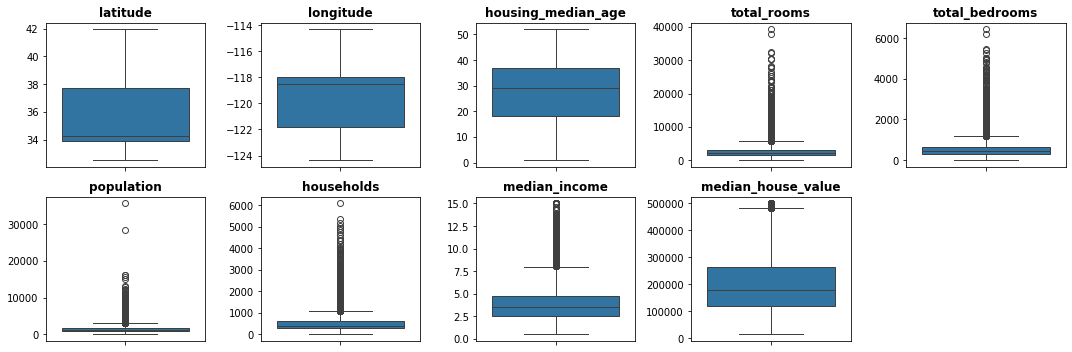

In [9]:
fig, axs = plt.subplots(ncols=5, nrows=2, figsize=(15, 5))
index = 0
axs = axs.flatten()

for i,col in enumerate(df_numeric.columns):
    sns.boxplot(y=col, data=df_numeric, ax=axs[i])
    axs[i].set_ylabel('')
    axs[i].set_title(col, fontweight='bold')
    
# Remove any unused subplots
for i in range(len(df_numeric.columns), len(axs)):
    fig.delaxes(axs[i])
    
plt.tight_layout()
plt.show()

- The box plots show strong skewness and many high-end outliers in the count and target variables, with more moderate spread in the geographic and age features.
- total_rooms, total_bedrooms, population, households, median_income, and median_house_value all have long upper whiskers with dense clusters of points, indicating many extreme high values rather than just a few anomalies.
- The lower ends are comparatively compact, so distributions are heavily right-skewed

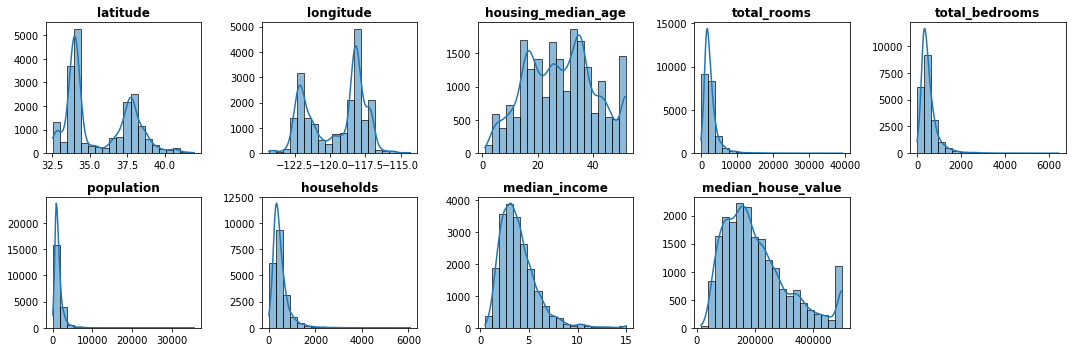

In [10]:
fig, axs = plt.subplots(ncols=5, nrows=2, figsize=(15, 5))
index = 0
axs = axs.flatten()

for i,col in enumerate(df_numeric.columns):
    sns.histplot(x=col, data=df_numeric, bins=20, kde=True, ax=axs[i])
    axs[i].set_xlabel('')
    axs[i].set_ylabel('')
    axs[i].set_title(col, fontweight='bold')
    
# Remove any unused subplots
for i in range(len(df_numeric.columns), len(axs)):
    fig.delaxes(axs[i])
    
plt.tight_layout()
plt.show()

- The histograms show strong right skew for most count and income variables, multimodal spatial distributions (geographical variables), and a capped, slightly left-skewed target distribution.
- Apply log or similar transformations to highly skewed features to reduce skew and heteroscedasticity.

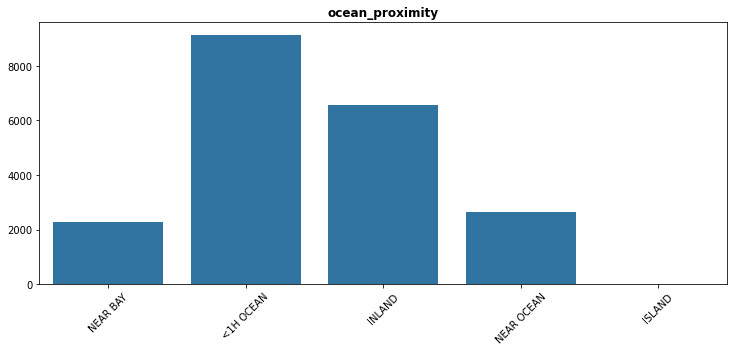

In [11]:
df_cat = df[cat_vars]

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(20, 5))
index = 0
axs = axs.flatten()

for i,col in enumerate(df_cat.columns):
    sns.countplot(x=col, data=df_cat, ax=axs[i])
    axs[i].set_xlabel('')
    axs[i].set_ylabel('')
    axs[i].set_title(col, fontweight='bold')
    
    axs[i].set_xticklabels(axs[i].xaxis.get_majorticklabels(), rotation=45)
    
    
# Remove any unused subplots
for i in range(len(df_cat.columns), len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.show()

- <1H OCEAN is the largest group, followed by INLAND, then NEAR OCEAN and NEAR BAY, while ISLAND is practically absent

## 4.2 Bivariate Analysis

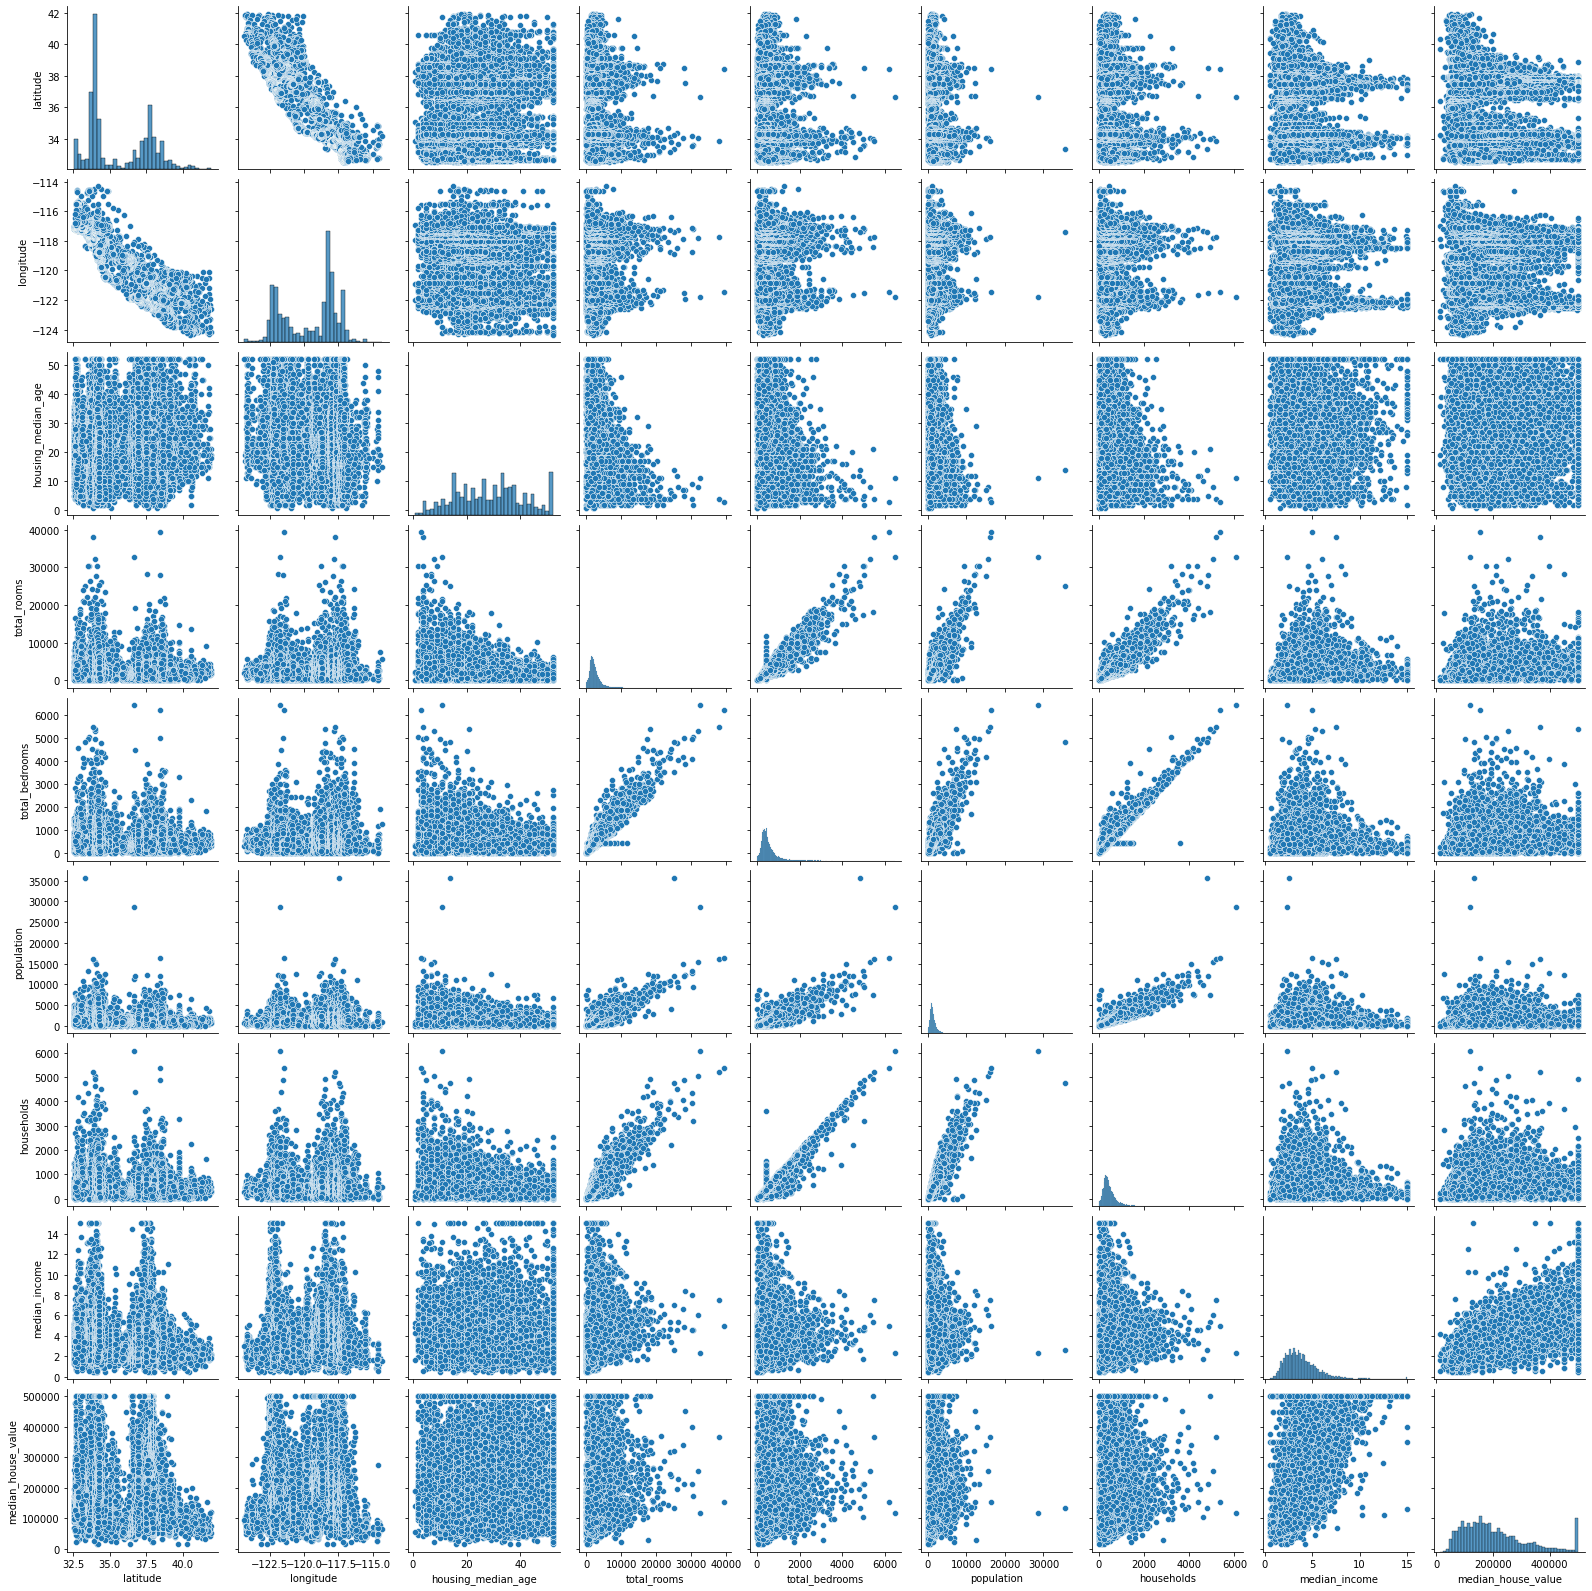

In [12]:
sns.pairplot(data=df[num_vars + target_var])
plt.show()

- The pair plot highlights a few strong linear relationships, substantial multicollinearity among size-related features, and a clear positive association between income and house value.
- median_house_value increases almost monotonically with median_income, giving a visibly tight upward trend;
- Relationships between median_house_value and total_rooms, total_bedrooms, population, and households are weaker and more diffuse, suggesting these raw counts add limited signal unless combined into density or ratio features.
- total_rooms, total_bedrooms, population, and households show near-linear trends with each other, indicating high multicollinearity that can destabilize linear models and inflate variance of coefficients.
- Plots involving latitude and longitude form curved or banded structures rather than straight lines, implying strong nonlinear spatial effects (e.g., coastal vs inland) that simple linear terms may not capture well.

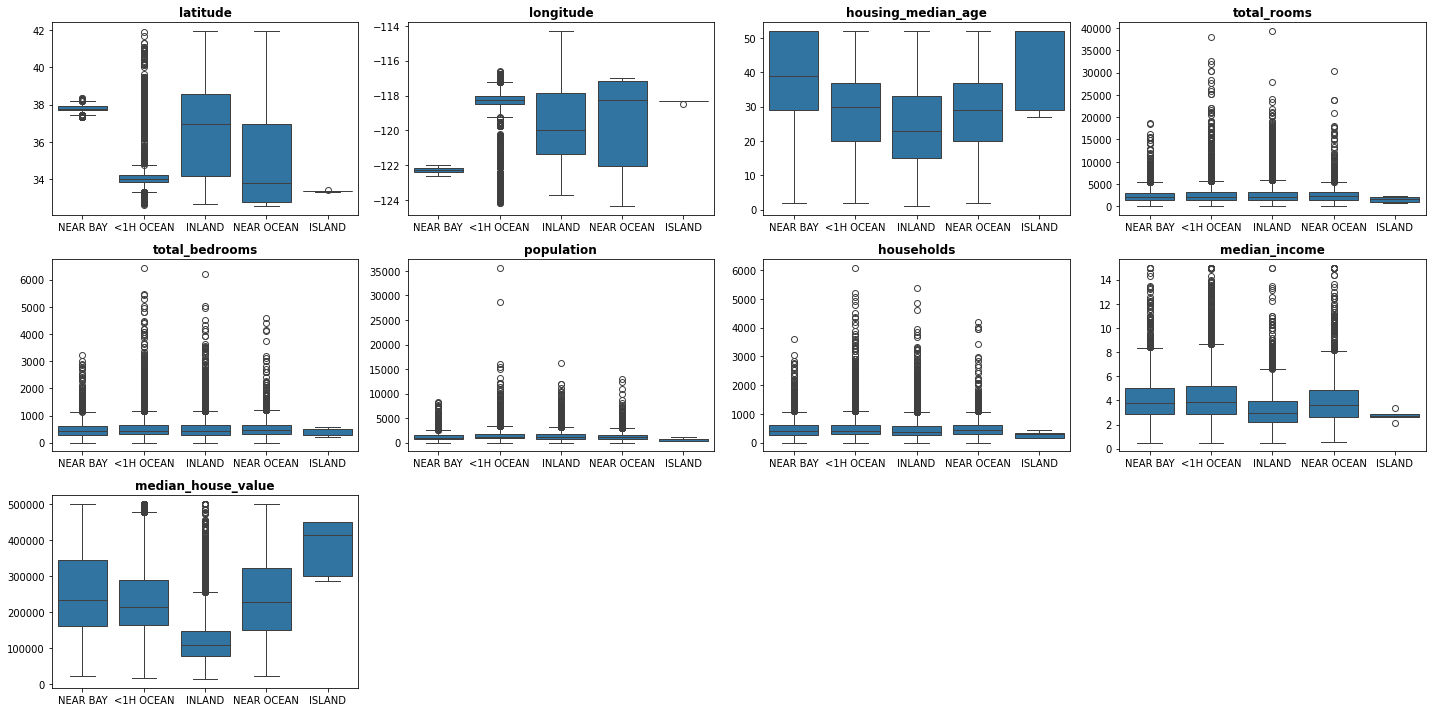

In [13]:
y_col = num_vars + target_var

x_col = ['ocean_proximity']

df_cat2 = df[y_col + x_col]

fig, axs = plt.subplots(ncols=4, nrows=round(len(y_col) / 3), figsize=(20, 10))
index = 0
axs = axs.flatten()

for i,col in enumerate(y_col):
    sns.boxplot(y=col, x='ocean_proximity', data=df_cat2, ax=axs[i])
    axs[i].set_ylabel('')
    axs[i].set_xlabel('')
    axs[i].set_title(col, fontweight='bold')
    
    axs[i].set_xticklabels(axs[i].xaxis.get_majorticklabels())
    
     
# Remove any unused subplots
for i in range(len(y_col), len(axs)):
    fig.delaxes(axs[i])
    
plt.tight_layout()
plt.show()

- NEAR BAY and NEAR OCEAN tend to have higher median_income than INLAND, with <1H OCEAN in between, suggesting wealthier households cluster closer to the coast.
- total_rooms, total_bedrooms, population, and households show overlapping distributions across ocean_proximity groups, implying that differences in house values by location are driven more by location and income than by raw block size.
- housing_median_age varies somewhat (e.g., some coastal areas skew older), but its between-group differences are smaller and likely secondary to income and location in explaining price variation.

# 5. Feature Engineering

## 5.1 Binning

In [14]:
# Bin housing_median_age as it is multimodal
age_bins = [0, 10, 20, 30, 40, 50, df['housing_median_age'].max()]
df['age_bins'] = pd.cut(df['housing_median_age'], bins=age_bins, labels=False, include_lowest=True)

## 5.2 Transformation

applying log(x+1) transformation as data contains zeroes

In [15]:
num_log_tran = ['total_rooms','total_bedrooms','population','households','median_income']

for col in num_log_tran:  
    df[f'{col}_Log'] = np.log1p(df[col])

log_col = [col for col in df.columns if col.endswith('_Log')]

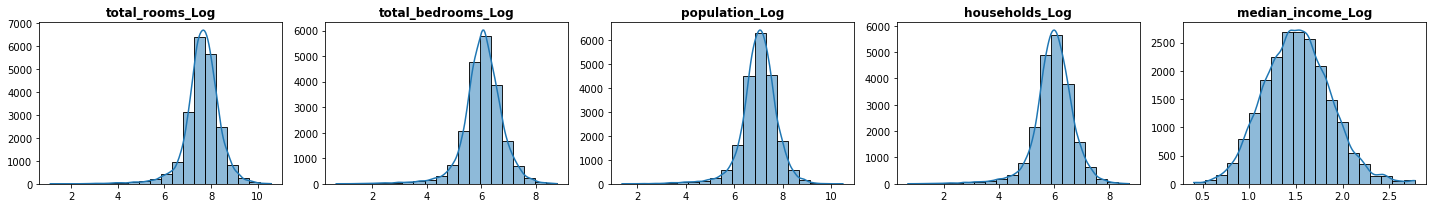

In [16]:
fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(20, 3))
index = 0
axs = axs.flatten()

for i,col in enumerate(log_col):
    sns.histplot(x=col, data=df, bins=20, kde=True, ax=axs[i])
    axs[i].set_xlabel('')
    axs[i].set_ylabel('')
    axs[i].set_title(col, fontweight='bold')
    
# Remove any unused subplots
for i in range(len(log_col), len(axs)):
    fig.delaxes(axs[i])
    
plt.tight_layout()
plt.show()

- Log Transformation has effectively normalized the distributions of most variables, as seen by the more symmetric, bell-shaped histograms.

## 5.3 Feature Creation

### 5.3.1 Ratio Features

In [17]:
df['room_per_household'] = df['total_rooms'] / df['households'].replace({0:np.nan})
df['bedroom_per_household'] = df['total_bedrooms'] / df['households'].replace({0:np.nan})
df['bedroom_Totalroom_ratio'] = df['total_bedrooms'] / df['total_rooms'].replace({0:np.nan})
df['population_per_household'] = df['population'] / df['households'].replace({0:np.nan})

### 5.3.2 One-hot (Nominal) Encoding
Unordered categorical variables are expanded into binary columns

In [18]:
ohe = OneHotEncoder(sparse=False, drop='first')

# ocean_proximity
ocean_prox_encoded = ohe.fit_transform(df[['ocean_proximity']])
ocean_prox_labels = ohe.get_feature_names_out(['ocean_proximity'])
df[ocean_prox_labels] = ocean_prox_encoded

# age_bins
age_bins_encoded = ohe.fit_transform(df[['age_bins']])
age_bins_labels = ohe.get_feature_names_out(['age_bins'])
df[age_bins_labels] = age_bins_encoded

### 5.3.3 Interaction features

In [19]:
# (income × location)
for label in ocean_prox_labels:
    df['income_' + label] = df['median_income'] * df[label]

# (income × age_bins)
for label in age_bins_labels:
    df['income_' + label] = df['median_income'] * df[label]

### 5.3.4 Transformed dataset

In [20]:
df_tran = df.drop(columns = num_vars + cat_vars + ['age_bins'])

df_tran.head()

,median_house_value,total_rooms_Log,total_bedrooms_Log,population_Log,households_Log,median_income_Log,room_per_household,bedroom_per_household,bedroom_Totalroom_ratio,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,age_bins_1,age_bins_2,age_bins_3,age_bins_4,age_bins_5,income_ocean_proximity_INLAND,income_ocean_proximity_ISLAND,income_ocean_proximity_NEAR BAY,income_ocean_proximity_NEAR OCEAN,income_age_bins_1,income_age_bins_2,income_age_bins_3,income_age_bins_4,income_age_bins_5
0,452600,6.781058,4.867534,5.777652,4.844187,2.232720,6.984127,1.023810,0.146591,2.555556,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,8.3252,0.0,0.0,0.0000,0.0,8.3252,0.0000
1,358500,8.867850,7.009409,7.784057,7.037906,2.230165,6.238137,0.971880,0.155797,2.109842,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,8.3014,0.0,0.0,8.3014,0.0,0.0000,0.0000
2,352100,7.291656,5.252273,6.208590,5.181784,2.111110,8.288136,1.073446,0.129516,2.802260,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,7.2574,0.0,0.0,0.0000,0.0,0.0000,7.2574
3,341300,7.150701,5.463832,6.326149,5.393628,1.893579,5.817352,1.073059,0.184458,2.547945,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5.6431,0.0,0.0,0.0000,0.0,0.0000,5.6431
4,342200,7.395108,5.638355,6.338594,5.560682,1.578195,6.281853,1.081081,0.172096,2.181467,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.8462,0.0,0.0,0.0000,0.0,0.0000,3.8462


## 5.4 Correlation Heatmap

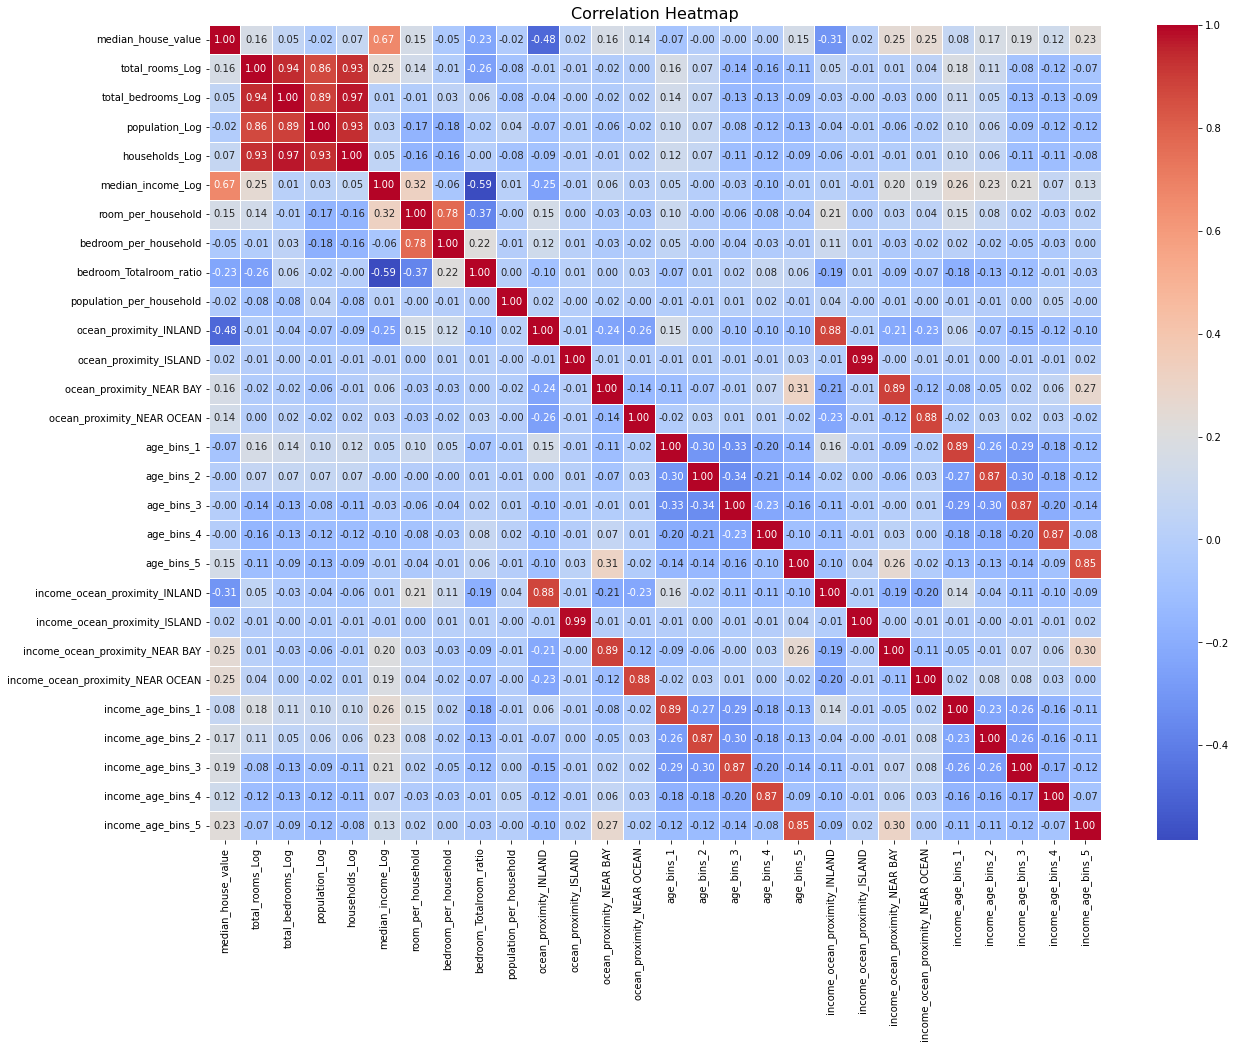

In [21]:
corr_matrix = df_tran.corr()

# --- Correlation Heatmap ---
plt.figure(figsize=(20,15))
sns.heatmap(
    corr_matrix, 
    annot=True,          # Show the correlation values on the heatmap
    fmt=".2f",           # Format the values to two decimal places
    cmap='coolwarm',     # Color map (coolwarm is excellent for showing positive/negative correlation)
    linewidths=.5,       # Add lines between cells for clarity
    cbar=True            # Show the color bar
)

plt.title('Correlation Heatmap', fontsize=16)
plt.show()

- median_income_Log has the highest positive correlation with median_house_value
- Interaction features such as income_ocean_proximity_NEAR BAY and income_ocean_proximity_NEAR OCEAN also show relatively strong positive correlations with the target, indicating that high income in coastal areas is especially predictive of higher house values.
- total_rooms_Log, total_bedrooms_Log, population_Log, and households_Log exhibit very high pairwise correlations
- room_per_household and population_per_household have moderate correlations with median_house_value and weaker correlations with each other, suggesting they provide complementary information about crowding and neighborhood density.
- One-hot ocean_proximity dummies by themselves have relatively low correlations with the target, but their income interactions are more predictive, which supports modeling location primarily through interaction terms rather than standalone dummies.
- age_bins and income_age_bins features are highly correlated with each other within their families, showing that adjacent bins carry similar information.

## 5.5 Dimensionality Reduction

### 5.5.1 Principal Component Analysis
For age_bins and Income_age_bins to capture nonlinearity without a large set of correlated dummies.

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

age_cols = [c for c in df_tran.columns if c.startswith("age_bins_")]
income_age_cols = [c for c in df_tran.columns if c.startswith("income_age_bins_")]

scaler = StandardScaler()

age_scaled = scaler.fit_transform(df_tran[age_cols])
income_age_scaled = scaler.fit_transform(df_tran[income_age_cols])

pca_age = PCA(n_components=3, random_state=42)
age_pcs = pca_age.fit_transform(age_scaled)

pca_income_age = PCA(n_components=4, random_state=42)
income_age_pcs = pca_income_age.fit_transform(income_age_scaled)

age_pcs_df = pd.DataFrame(
    age_pcs,
    columns=[f"age_pca_{i+1}" for i in range(age_pcs.shape[1])],
    index=df.index,
)

income_age_pcs_df = pd.DataFrame(
    income_age_pcs,
    columns=[f"income_age_pca_{i+1}" for i in range(income_age_pcs.shape[1])],
    index=df.index,
)

# Explained variance to determine ideal number of PCA components
print("Age PCA:")
print("Explained variance ratio:", pca_age.explained_variance_ratio_)
print("Cumulative explained variance:", np.cumsum(pca_age.explained_variance_ratio_))
print("\nIncome-age PCA:")
print("Explained variance ratio:", pca_income_age.explained_variance_ratio_)
print("Cumulative explained variance:", np.cumsum(pca_income_age.explained_variance_ratio_))

Age PCA:
Explained variance ratio: [0.2697923  0.2603672  0.23418836]
Cumulative explained variance: [0.2697923  0.5301595  0.76434786]

Income-age PCA:
Explained variance ratio: [0.25335099 0.24667246 0.2260161  0.21186929]
Cumulative explained variance: [0.25335099 0.50002345 0.72603955 0.93790884]


In [23]:
df_pca = pd.concat([df_tran.drop(columns=age_cols + income_age_cols),
                    age_pcs_df,
                    income_age_pcs_df],
                   axis=1)

df_pca.head()

,median_house_value,total_rooms_Log,total_bedrooms_Log,population_Log,households_Log,median_income_Log,room_per_household,bedroom_per_household,bedroom_Totalroom_ratio,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,income_ocean_proximity_INLAND,income_ocean_proximity_ISLAND,income_ocean_proximity_NEAR BAY,income_ocean_proximity_NEAR OCEAN,age_pca_1,age_pca_2,age_pca_3,income_age_pca_1,income_age_pca_2,income_age_pca_3,income_age_pca_4
0,452600,6.781058,4.867534,5.777652,4.844187,2.232720,6.984127,1.023810,0.146591,2.555556,0.0,0.0,1.0,0.0,0.0,0.0,8.3252,0.0,-0.217606,0.054669,2.716822,-0.395092,0.021517,5.730335,-1.750318
1,358500,8.867850,7.009409,7.784057,7.037906,2.230165,6.238137,0.971880,0.155797,2.109842,0.0,0.0,1.0,0.0,0.0,0.0,8.3014,0.0,-1.084691,-1.598736,-0.588430,-1.838696,-3.095449,-1.182106,-0.455358
2,352100,7.291656,5.252273,6.208590,5.181784,2.111110,8.288136,1.073446,0.129516,2.802260,0.0,0.0,1.0,0.0,0.0,0.0,7.2574,0.0,-0.160972,0.037569,0.782444,-0.212903,0.010773,1.158727,6.198065
3,341300,7.150701,5.463832,6.326149,5.393628,1.893579,5.817352,1.073059,0.184458,2.547945,0.0,0.0,1.0,0.0,0.0,0.0,5.6431,0.0,-0.160972,0.037569,0.782444,-0.171686,0.008645,0.914457,4.828427
4,342200,7.395108,5.638355,6.338594,5.560682,1.578195,6.281853,1.081081,0.172096,2.181467,0.0,0.0,1.0,0.0,0.0,0.0,3.8462,0.0,-0.160972,0.037569,0.782444,-0.125807,0.006276,0.642557,3.303865


### 5.5.2 Correlation threshold

In [24]:
target = 'median_house_value'

# Calculate absolute correlation matrix
corr_matrix = df_pca.corr().abs()

# Select features with correlation > 0.1 with the target
target_corr = corr_matrix[target]
selected_features = target_corr[target_corr > 0.1].index.drop(target)

# Subset correlation matrix to only these selected features
corr_sub_matrix = corr_matrix.loc[selected_features, selected_features]

# Find features with any correlation > 0.9 with other features
upper = corr_sub_matrix.where(np.triu(np.ones(corr_sub_matrix.shape), k=1).astype(bool))
high_corr_features = [col for col in upper.columns if any(upper[col] > 0.9)]

# Final feature list excludes highly correlated features
final_feats = [feat for feat in selected_features if feat not in high_corr_features]

In [25]:
df_final = df_pca[final_feats + target_var]

df_final.head()

,total_rooms_Log,median_income_Log,room_per_household,bedroom_Totalroom_ratio,ocean_proximity_INLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,income_ocean_proximity_INLAND,income_ocean_proximity_NEAR BAY,income_ocean_proximity_NEAR OCEAN,income_age_pca_4,median_house_value
0,6.781058,2.232720,6.984127,0.146591,0.0,1.0,0.0,0.0,8.3252,0.0,-1.750318,452600
1,8.867850,2.230165,6.238137,0.155797,0.0,1.0,0.0,0.0,8.3014,0.0,-0.455358,358500
2,7.291656,2.111110,8.288136,0.129516,0.0,1.0,0.0,0.0,7.2574,0.0,6.198065,352100
3,7.150701,1.893579,5.817352,0.184458,0.0,1.0,0.0,0.0,5.6431,0.0,4.828427,341300
4,7.395108,1.578195,6.281853,0.172096,0.0,1.0,0.0,0.0,3.8462,0.0,3.303865,342200


# 6. Modeling

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# Assign features (X) and target (y)
X = df_final[final_feats]
y = df_final['median_house_value']

# Split data into train and test sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Fit linear regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predict on test data
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:     ", mse)
print("Root Mean Squared Error:", rmse)
print("R^2 Score:              ", r2)

Mean Squared Error:      5995415585.609892
Root Mean Squared Error: 77430.06900171207
R^2 Score:               0.5432203899966364


**Insights & Recommendations:**
- With R² ≈ 0.54, the model is capturing major drivers like income, rooms per household, and income–location interactions, but a large share of variability remains unexplained
- The RMSE of roughly 77,000 dollars implies that typical predictions are off by that amount on the original price scale, which is too large if precise pricing is required.
- This suggests that income and location-based features are strong but that remaining nonlinear and interaction effects are not fully modeled.
- This linear model can be considered as a baseline, and more advanced models can be explored that can better capture the nonlinear spatial and socioeconomic structure.